# Phase 05: Data Preprocessing & Feature Engineering
**AI-Powered Transaction Risk Scoring System**

### Notebook Objective
This notebook demonstrates the end-to-end data preprocessing, cleaning, feature engineering, and data leakage prevention pipeline for transaction risk scoring.

### Key Milestones:
1. **Dataset Validation & Cleaning:** Validate schema integrity, missing values, infinite values, and resolve duplicate records.
2. **Stratified Splitting:** Create 70% Train, 15% Validation, and 15% Test partitions while strictly preserving minority class fraud representation (~0.17%).
3. **Feature Engineering:**
   - Cyclic 24-hour temporal encoding (`hour_sin`, `hour_cos`) from elapsed transaction seconds.
   - Variance-stabilizing logarithmic transformation (`np.log1p`) of skewed monetary amounts.
   - Preservation of orthogonal PCA components `V1`–`V28`.
4. **Leakage Prevention & Scaling:** Fit Scikit-learn `RobustScaler` **strictly** on the training partition and apply to validation/test sets.
5. **Serialization:** Persist the reusable `preprocessor.joblib` artifact for offline model training (Phase 6) and online FastAPI inference (Phase 8).
6. **Online Inference Verification:** Test transformation on a single transaction dictionary payload.


In [1]:
import sys
from pathlib import Path

# Add project root to sys.path for modular imports
project_root = Path.cwd().resolve().parent.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from ml.src.config import (
    RAW_DATA_FILE,
    PROCESSED_DATA_DIR,
    SAVED_MODELS_DIR,
    PREPROCESSOR_ARTIFACT_FILE,
    RANDOM_SEED,
    TARGET_COLUMN,
    TIME_COLUMN,
    AMOUNT_COLUMN,
    PCA_COLUMNS,
    ENGINEERED_FEATURE_NAMES,
)
from ml.src.preprocessing.data_cleaning import (
    load_raw_data,
    validate_raw_data,
    clean_dataset,
    split_dataset,
)
from ml.src.preprocessing.feature_engineering import TransactionFeatureTransformer
from ml.src.preprocessing.pipeline import (
    build_preprocessing_pipeline,
    save_preprocessor,
    load_preprocessor,
)

print(f"Project Root: {project_root}")
print(f"Raw Dataset Path: {RAW_DATA_FILE}")


Project Root: E:\Project\AI Transaction Risk System
Raw Dataset Path: E:\Project\AI Transaction Risk System\ml\data\raw\creditcard.csv


## 1. Load & Validate Raw Dataset

In [2]:
raw_df = load_raw_data(RAW_DATA_FILE)
validate_raw_data(raw_df)

print(f"Raw Dataset Dimensions: {raw_df.shape[0]:,} rows, {raw_df.shape[1]} columns")
display(raw_df.head(5))


Raw Dataset Dimensions: 284,807 rows, 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data Cleaning & Duplicate Handling

During Phase 4 EDA, 1,081 duplicate transactions were detected across the anonymized dataset. In credit card transaction modeling without explicit cardholder identifiers, duplicate records present across training and validation folds cause exact row leakage.

We systematically remove duplicate transactions, preserving the first instance.

In [3]:
cleaned_df, cleaning_metrics = clean_dataset(raw_df, drop_duplicates_flag=True)

print("=== Data Cleaning Report ===")
for k, v in cleaning_metrics.items():
    print(f"  {k}: {v}")


=== Data Cleaning Report ===
  initial_rows: 284807
  initial_cols: 31
  total_null_values: 0
  columns_with_nulls: {}
  total_inf_values: 0
  total_duplicates: 1081
  duplicates_by_class: {0: 1062, 1: 19}
  drop_duplicates_applied: True
  final_rows: 283726
  removed_rows: 1081


## 3. Stratified Train / Validation / Test Split

We partition the cleaned dataset into:
- **Training Set (70%):** Model training and preprocessor fitting.
- **Validation Set (15%):** Hyperparameter tuning and threshold calibration.
- **Test Set (15%):** Final out-of-sample generalization evaluation.

Stratification on `Class` ensures exact proportional minority class representation across all three sets.

In [4]:
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(
    cleaned_df,
    target_col=TARGET_COLUMN,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    random_seed=RANDOM_SEED,
)

split_summary = pd.DataFrame({
    "Partition": ["Train (70%)", "Validation (15%)", "Test (15%)"],
    "Sample Count": [len(X_train), len(X_val), len(X_test)],
    "Legitimate (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Fraudulent (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
    "Fraud Rate (%)": [
        f"{(y_train == 1).mean():.5%}",
        f"{(y_val == 1).mean():.5%}",
        f"{(y_test == 1).mean():.5%}",
    ],
    "Imbalance Ratio": [
        f"{(y_train == 0).sum() / (y_train == 1).sum():.2f} : 1",
        f"{(y_val == 0).sum() / (y_val == 1).sum():.2f} : 1",
        f"{(y_test == 0).sum() / (y_test == 1).sum():.2f} : 1",
    ]
})

display(split_summary)


,Partition,Sample Count,Legitimate (0),Fraudulent (1),Fraud Rate (%),Imbalance Ratio
0,Train (70%),198608,198277,331,0.16666%,599.02 : 1
1,Validation (15%),42559,42488,71,0.16683%,598.42 : 1
2,Test (15%),42559,42488,71,0.16683%,598.42 : 1


## 4. Feature Engineering Architecture

### A. Temporal Cyclic Encoding (`hour_sin`, `hour_cos`)
- `Time` represents elapsed seconds from dataset start ($0$ to $172,792$ seconds, spanning 48 hours).
- `hour_of_day = (Time / 3600.0) % 24.0`
- Cyclic trigonometric encoding projects 24-hour time onto a continuous unit circle:
  $$\text{hour}_{\sin} = \sin\left(2\pi \cdot \frac{\text{hour}}{24}\right), \quad \text{hour}_{\cos} = \cos\left(2\pi \cdot \frac{\text{hour}}{24}\right)$$
- *Benefit:* Captures circular temporal continuity (e.g. 23:59 is mathematically adjacent to 00:01) without imposing artificial linear boundaries.

### B. Amount Transformation & Robust Scaling
- `Amount` is highly right-skewed with extreme values up to €25,691.
- `amount_log = log1p(Amount)` stabilizes variance and compresses high-dollar outliers.
- `RobustScaler()` standardizes `amount_log` using median and IQR, preventing remaining extreme values from distorting gradient updates.

### C. PCA Component Preservation
- Features `V1`–`V28` are already orthogonal, centered principal components and are passed through directly in deterministic order.


## 5. Fit Preprocessor Pipeline (Strict Leakage Prevention)

We fit the Scikit-learn preprocessing pipeline **strictly on `X_train`**. Validation and test data are never seen by the scaler.

In [5]:
pipeline = build_preprocessing_pipeline(scale_amount=True)

# Fit strictly on X_train
pipeline.fit(X_train)

transformer = pipeline.named_steps["feature_transformer"]
print("Preprocessor successfully fitted on training partition.")
print(f"Output Feature Count: {len(transformer.get_feature_names_out())}")
print(f"Output Feature Names: {transformer.get_feature_names_out()}")


Preprocessor successfully fitted on training partition.
Output Feature Count: 31
Output Feature Names: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'hour_sin', 'hour_cos', 'amount_log']


## 6. Transform Partitions & Verify Leakage Prevention

In [6]:
X_train_proc = transformer.transform_to_dataframe(X_train)
X_val_proc = transformer.transform_to_dataframe(X_val)
X_test_proc = transformer.transform_to_dataframe(X_test)

print(f"Transformed X_train shape: {X_train_proc.shape}")
print(f"Transformed X_val shape:   {X_val_proc.shape}")
print(f"Transformed X_test shape:  {X_test_proc.shape}")

# Data Leakage Verification:
train_raw_amount_log = np.log1p(X_train[AMOUNT_COLUMN].values)
train_median = float(np.median(train_raw_amount_log))
fitted_scaler_median = float(transformer.amount_scaler.center_[0])

print(f"\nLeakage Verification:")
print(f"  Training set amount_log median: {train_median:.6f}")
print(f"  Fitted Scaler center:           {fitted_scaler_median:.6f}")
assert np.isclose(train_median, fitted_scaler_median), "Leakage check failed!"
print("  ✓ Scaler parameters were derived exclusively from the training split.")


Transformed X_train shape: (198608, 31)
Transformed X_val shape:   (42559, 31)
Transformed X_test shape:  (42559, 31)

Leakage Verification:
  Training set amount_log median: 3.138966
  Fitted Scaler center:           3.138966
  ✓ Scaler parameters were derived exclusively from the training split.


## 7. Engineered Feature Visualizations

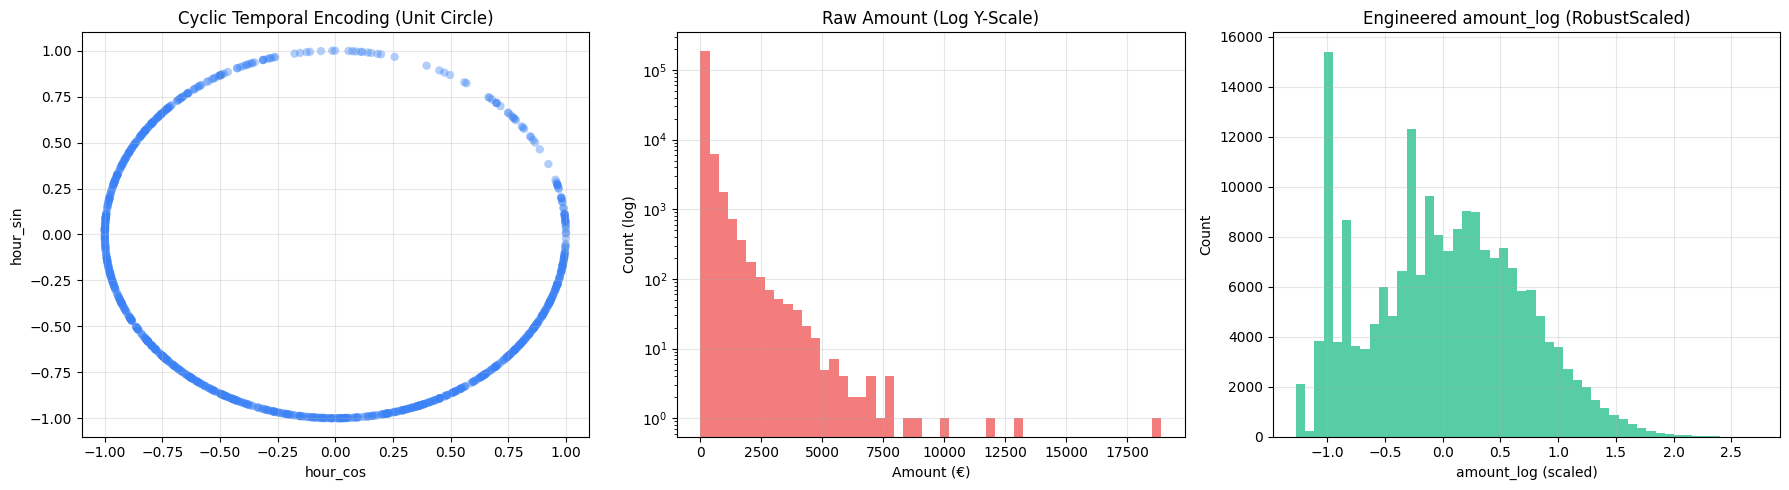

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Cyclic Hour Scatter Plot
sample_indices = np.random.choice(len(X_train_proc), size=1000, replace=False)
axes[0].scatter(
    X_train_proc.loc[sample_indices, "hour_cos"],
    X_train_proc.loc[sample_indices, "hour_sin"],
    alpha=0.4,
    c="#3b82f6",
    edgecolors="none",
)
axes[0].set_title("Cyclic Temporal Encoding (Unit Circle)")
axes[0].set_xlabel("hour_cos")
axes[0].set_ylabel("hour_sin")
axes[0].grid(True, alpha=0.3)

# 2. Raw vs Log Amount Distribution
axes[1].hist(X_train[AMOUNT_COLUMN], bins=50, color="#ef4444", alpha=0.7, log=True)
axes[1].set_title("Raw Amount (Log Y-Scale)")
axes[1].set_xlabel("Amount (€)")
axes[1].set_ylabel("Count (log)")
axes[1].grid(True, alpha=0.3)

# 3. Transformed & Scaled Amount Distribution
axes[2].hist(X_train_proc["amount_log"], bins=50, color="#10b981", alpha=0.7)
axes[2].set_title("Engineered amount_log (RobustScaled)")
axes[2].set_xlabel("amount_log (scaled)")
axes[2].set_ylabel("Count")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Persist Processed Datasets & Preprocessor Artifact

In [8]:
# Combine features and target for processed CSV outputs
train_df = X_train_proc.copy()
train_df[TARGET_COLUMN] = y_train.values

val_df = X_val_proc.copy()
val_df[TARGET_COLUMN] = y_val.values

test_df = X_test_proc.copy()
test_df[TARGET_COLUMN] = y_test.values

# Save CSVs
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
val_df.to_csv(PROCESSED_DATA_DIR / "validation.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# Save Preprocessor Artifact
artifact_path = save_preprocessor(pipeline, PREPROCESSOR_ARTIFACT_FILE)

print("Saved Processed Files:")
print(f"  Train CSV:      {PROCESSED_DATA_DIR / 'train.csv'} ({train_df.shape})")
print(f"  Validation CSV: {PROCESSED_DATA_DIR / 'validation.csv'} ({val_df.shape})")
print(f"  Test CSV:       {PROCESSED_DATA_DIR / 'test.csv'} ({test_df.shape})")
print(f"  Saved Artifact: {artifact_path}")


Saved Processed Files:
  Train CSV:      E:\Project\AI Transaction Risk System\ml\data\processed\train.csv ((198608, 32))
  Validation CSV: E:\Project\AI Transaction Risk System\ml\data\processed\validation.csv ((42559, 32))
  Test CSV:       E:\Project\AI Transaction Risk System\ml\data\processed\test.csv ((42559, 32))
  Saved Artifact: E:\Project\AI Transaction Risk System\ml\saved_models\preprocessor.joblib


## 9. Artifact Reload & Reproducibility Verification

In [9]:
loaded_pipeline = load_preprocessor(artifact_path)

# Test on test set sample
sample_test_X = X_test.head(100)
orig_output = pipeline.transform(sample_test_X)
reload_output = loaded_pipeline.transform(sample_test_X)

np.testing.assert_allclose(orig_output, reload_output)
print("✓ Deserialized preprocessor produces 100% identical transformations to the in-memory pipeline.")


✓ Deserialized preprocessor produces 100% identical transformations to the in-memory pipeline.


## 10. Online Single-Transaction Inference Demonstration

In production (Phase 8), FastAPI will receive single-record JSON payloads. We verify that `TransactionFeatureTransformer` handles single-record dictionary payloads without requiring full DataFrame overhead.

In [10]:
# Simulate a live transaction payload arriving via REST API
sample_transaction_payload = {
    "Time": 86400.0, # Exactly 24h from epoch
    "Amount": 249.50,
}
for col in PCA_COLUMNS:
    sample_transaction_payload[col] = float(np.random.normal(0, 1))

online_features = loaded_pipeline.transform(sample_transaction_payload)

print("Online Inference Preprocessing Output:")
print(f"  Input Payload:  Time={sample_transaction_payload['Time']}, Amount=€{sample_transaction_payload['Amount']}")
print(f"  Transformed Shape: {online_features.shape}")
print(f"  Sample Feature Vector (first 5 features): {online_features[0, :5]}")
print(f"  Engineered hour_sin:  {online_features[0, 28]:.4f}")
print(f"  Engineered hour_cos:  {online_features[0, 29]:.4f}")
print(f"  Engineered amount_log (scaled): {online_features[0, 30]:.4f}")


Online Inference Preprocessing Output:
  Input Payload:  Time=86400.0, Amount=€249.5
  Transformed Shape: (1, 31)
  Sample Feature Vector (first 5 features): [ 1.06643543 -0.43920063 -0.88251599  0.01562622  0.78486572]
  Engineered hour_sin:  0.0000
  Engineered hour_cos:  1.0000
  Engineered amount_log (scaled): 0.9679


## 11. Summary & Recommendations for Phase 6

### Summary of Accomplishments:
1. **Clean Dataset Established:** 1,081 duplicate transactions dropped; 0 missing/null values across 283,726 unique transactions.
2. **Stratified Split:** 198,608 Train (331 fraud), 42,559 Val (71 fraud), 42,559 Test (71 fraud) with exact 0.1668% fraud representation.
3. **Engineered Features:** 31 total features (`V1`–`V28`, `hour_sin`, `hour_cos`, `amount_log`).
4. **Data Leakage Prevented:** Scalers fitted exclusively on `X_train`.
5. **Joblib Artifact Serialized:** `ml/saved_models/preprocessor.joblib` created and verified for both batch training and online single-transaction serving.

### Hand-off to Phase 06 (Model Training & Evaluation):
- **Model Choice:** `xgboost.XGBClassifier`
- **Class Imbalance Handling:** Configure `scale_pos_weight = 599.0` or tune on validation set PR-AUC.
- **Evaluation Priority:** Optimize **PR-AUC (Average Precision)** and **Recall@Precision** over ROC-AUC.
